# 03 · Costo por error, interpretabilidad y API

**Supuestos:** revisar una alerta cuesta 5 EUR; un fraude no detectado cuesta el 100 % de su `Amount`; un fraude alertado se bloquea sin pérdida. El umbral se elige **en validación** (mínimo costo) y se aplica tal cual en prueba.

In [1]:
import json, os, sys, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
RAIZ = Path.cwd() if (Path.cwd() / 'src').is_dir() else Path.cwd().parent  # raíz del proyecto o notebooks/
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ / 'src'))
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
pd.set_option('display.width', 160)
R = RAIZ / 'reports'
res = json.loads((R / 'resultados.json').read_text(encoding='utf-8'))

In [2]:
c = pd.read_csv(R / 'costo_prueba.csv')
c[['nombre', 'alertas', 'fraudes_detectados', 'fraudes_perdidos', 'costo_total_eur', 'costo_ic_inf', 'costo_ic_sup', 'ahorro_vs_sin_modelo_pct']]

,nombre,alertas,fraudes_detectados,fraudes_perdidos,costo_total_eur,costo_ic_inf,costo_ic_sup,ahorro_vs_sin_modelo_pct
0,Regla por monto,98,0,75,"8,219.2600","4,124.5395","13,397.0992",-6.3395
1,Regresión logística,88,54,21,"3,439.1200","1,305.6708","6,495.1935",55.5052
2,Isolation Forest (sin etiquetas),1018,44,31,"8,504.5700","6,221.1415","11,658.5840",-10.0308
3,Isolation Forest (solo normales),906,39,36,"8,343.3400","5,957.4038","11,616.9295",-7.9449
4,LOF novelty (solo normales),166,54,21,"4,598.1800","1,754.0277","8,238.0202",40.5094
5,Autoencoder (solo normales),405,42,33,"5,451.8800","3,150.7108","8,481.5897",29.4644
6,LightGBM sin ajuste,172,62,13,"3,237.4800","1,181.0670","6,141.9880",58.1140
7,LightGBM con pesos,157,59,16,"3,650.5200","1,520.2190","6,719.8267",52.7701
8,LightGBM con submuestreo 1:20,59,56,19,"2,934.0300",836.3115,"5,680.3842",62.0400
9,Híbrido: LightGBM + anomalías,124,58,17,"3,257.2700","1,176.8390","6,007.5110",57.8579


### Recalcular el umbral del modelo servido desde las predicciones de validación

In [3]:
from fraude.costo import elegir_umbral, costo_total
pv = pd.read_parquet(R / 'predicciones_validacion.parquet')
pt = pd.read_parquet(R / 'predicciones_prueba.parquet')
srv = res['modelo_servido']
u, curva = elegir_umbral(pv.Class, pv.Amount, pv[f's_{srv}'], 5.0, 1.0)
fila = c.set_index('modelo').loc[srv]
assert abs(u - fila['umbral']) < 1e-12
assert abs(costo_total(pt.Class, pt.Amount, pt[f's_{srv}'] >= u, 5.0) - fila['costo_total_eur']) < 1e-6
print(f'Umbral {u:.4f} → {int((pt[f"s_{srv}"] >= u).sum())} alertas en prueba, costo {fila.costo_total_eur:,.2f} EUR ✔')

Umbral 0.0088 → 157 alertas en prueba, costo 3,650.52 EUR ✔


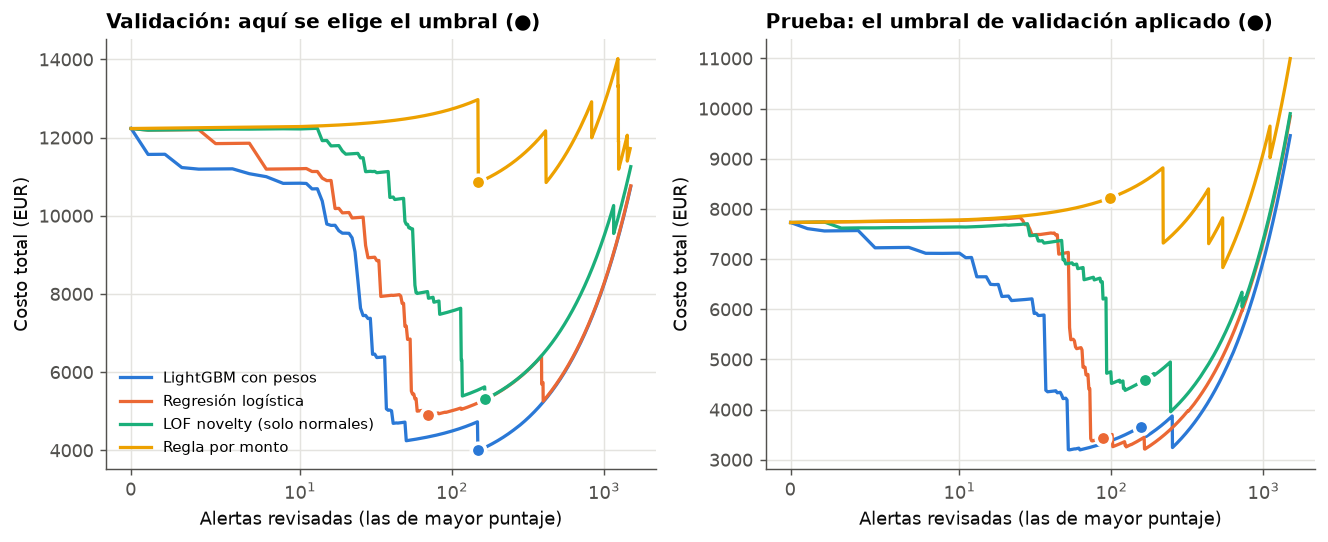

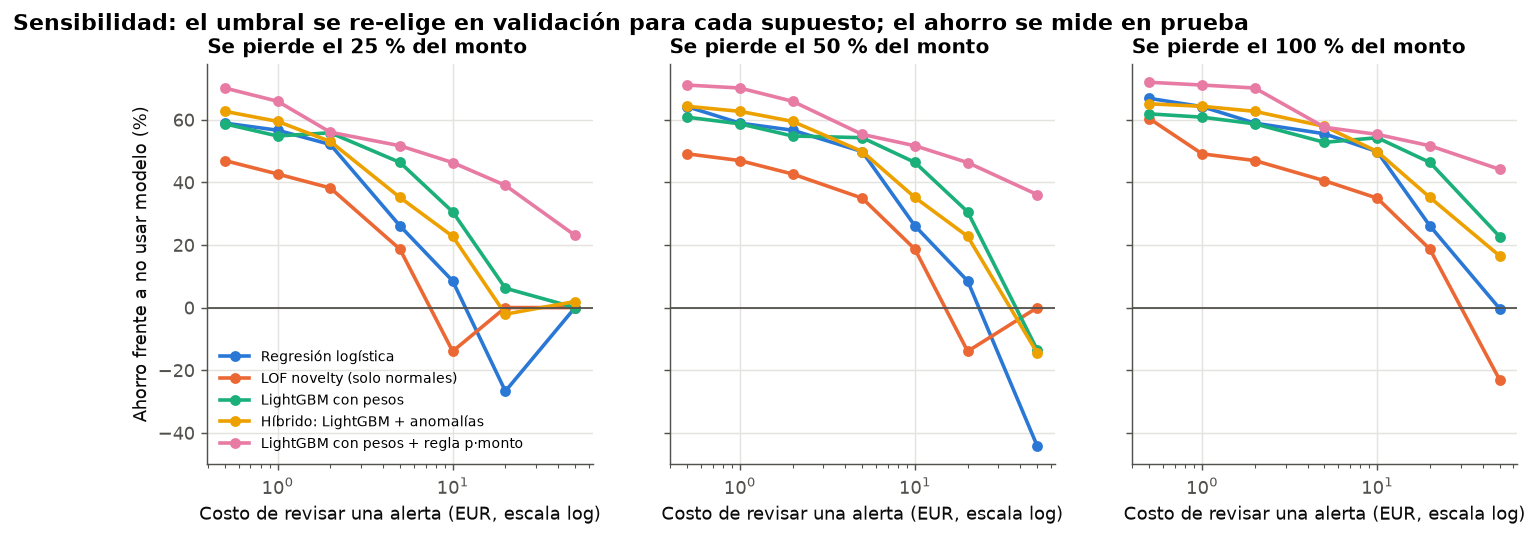

In [4]:
display(Image(filename=str(R / 'figures' / '05_curva_costo.png')))
display(Image(filename=str(R / 'figures' / '06_sensibilidad_costo.png')))

In [5]:
s = pd.read_csv(R / 'sensibilidad_costo.csv')
s.pivot_table(index=['fraccion_perdida', 'costo_revision_eur'], columns='modelo', values='ahorro_vs_sin_modelo_pct').round(1)

modelo                               hibrido  lgbm_pesos      lof  logistica  perdida_esperada
fraccion_perdida costo_revision_eur                                                           
0.2500           0.5000              62.7000     58.7000  47.0000    58.9000           70.1000
                 1.0000              59.5000     54.8000  42.7000    56.6000           65.9000
                 2.0000              53.0000     55.8000  38.2000    52.1000           56.0000
                 5.0000              35.2000     46.4000  18.6000    26.1000           51.7000
                 10.0000             22.7000     30.6000 -14.0000     8.5000           46.3000
                 20.0000             -2.1000      6.2000   0.0000   -26.7000           39.0000
                 50.0000              1.9000      0.0000   0.0000     0.0000           23.0000
0.5000           0.5000              64.3000     60.8000  49.1000    64.2000           71.1000
                 1.0000              62.7000     58.7000  47.0000    58.9000           70.1000
                 2.0000              59.5000     54.8000  42.7000    56.6000           65.9000
                 5.0000              49.8000     54.3000  34.9000    49.8000           55.3000
                 10.0000             35.2000     46.4000  18.6000    26.1000           51.7000
                 20.0000             22.7000     30.6000 -14.0000     8.5000           46.3000
                 50.0000            -14.5000    -13.6000   0.0000   -44.3000           36.1000
1.0000           0.5000              65.1000     61.9000  60.3000    66.8000           72.0000
                 1.0000              64.3000     60.8000  49.1000    64.2000           71.1000
                 2.0000              62.7000     58.7000  47.0000    58.9000           70.1000
                 5.0000              57.9000     52.8000  40.5000    55.5000           57.6000
                 10.0000             49.8000     54.3000  34.9000    49.8000           55.3000
                 20.0000             35.2000     46.4000  18.6000    26.1000           51.7000
                 50.0000             16.5000     22.7000 -23.0000    -0.3000           44.2000

## SHAP del modelo servido

V1–V28 son componentes PCA **anónimas**: SHAP dice *qué* componente empuja la decisión, pero no puede traducirse a «país», «comercio» u «hora». Sirve para auditar estabilidad y deriva, no para explicar al cliente.

,variable,shap_medio_abs,shap_medio_abs_fraudes
0,V14,0.8342,8.8216
1,V11,0.7996,1.0567
2,V4,0.7305,4.1264
3,V1,0.7228,0.4397
4,V8,0.6587,1.0527
5,V22,0.5711,0.6076
6,V5,0.5699,0.2906
7,V7,0.5265,1.4032
8,V12,0.4878,3.9562
9,V18,0.4814,0.6048


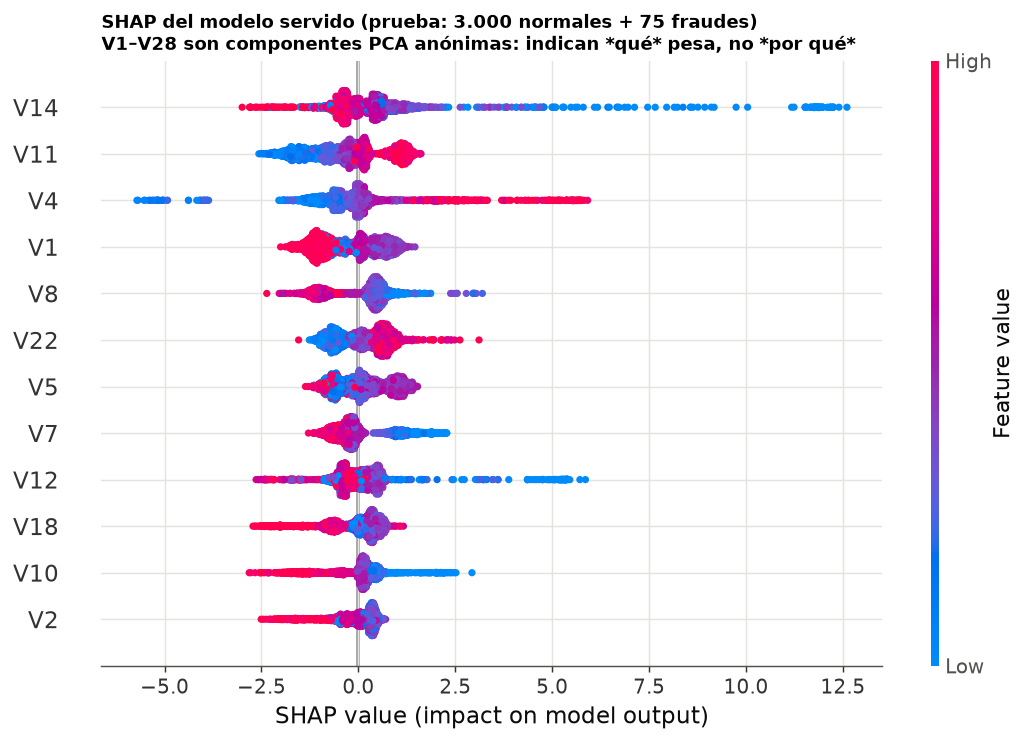

In [6]:
display(pd.read_csv(R / 'shap_importancia.csv').head(10))
display(Image(filename=str(R / 'figures' / '08_shap_resumen.png')))

## API `/puntuar` (FastAPI, probada con `TestClient`)

In [7]:
from fastapi.testclient import TestClient
from api.main import app
cliente = TestClient(app)
muestra = pd.read_csv(RAIZ / 'data' / 'muestra' / 'transacciones_prueba_muestra.csv')
ejemplo = pd.concat([muestra[muestra.Class == 1].head(3), muestra[muestra.Class == 0].head(3)])
r = cliente.post('/puntuar', json={'transacciones': ejemplo.drop(columns=['Time', 'Class']).to_dict('records')})
print(r.status_code)
pd.concat([ejemplo[['Amount', 'Class']].reset_index(drop=True), pd.DataFrame(r.json()['resultados'])], axis=1)

200


,Amount,Class,puntaje_modelo,probabilidad_fraude_calibrada,alerta_umbral_costo,perdida_esperada_eur,alerta_perdida_esperada,error_reconstruccion_ae,percentil_anomalia_ae
0,1.1800,1,1.0000,0.9782,True,1.1543,False,6.8924,99
1,2.2200,1,0.2128,0.0712,True,0.1580,False,0.4647,77
2,0.7700,1,1.0000,0.9665,True,0.7442,False,7.4884,99
3,19.6500,0,0.0000,0.0001,False,0.0016,False,0.1593,16
4,8.9200,0,0.0000,0.0001,False,0.0011,False,1.5988,97
5,12.5600,0,0.0000,0.0001,False,0.0009,False,0.1700,19
